Reading package lists...
Building dependency tree...
Reading state information...
graphviz is already the newest version (2.42.2-9ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.

=== Entrenando modelo con 1 capa(s) oculta(s) ===
Producción predicha para 100 kg/ha: 6.80 ton/ha | Loss final: 0.000156

=== Entrenando modelo con 2 capa(s) oculta(s) ===
Producción predicha para 100 kg/ha: 6.80 ton/ha | Loss final: 0.000040

=== Entrenando modelo con 3 capa(s) oculta(s) ===
Producción predicha para 100 kg/ha: 6.80 ton/ha | Loss final: 0.000015


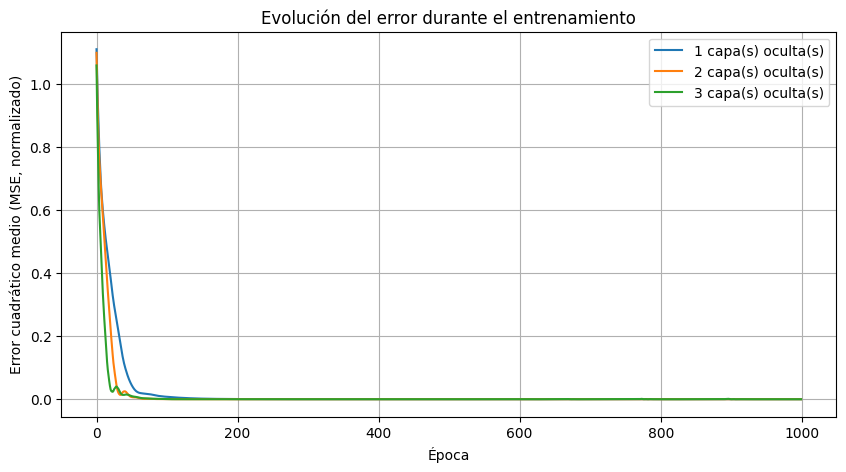

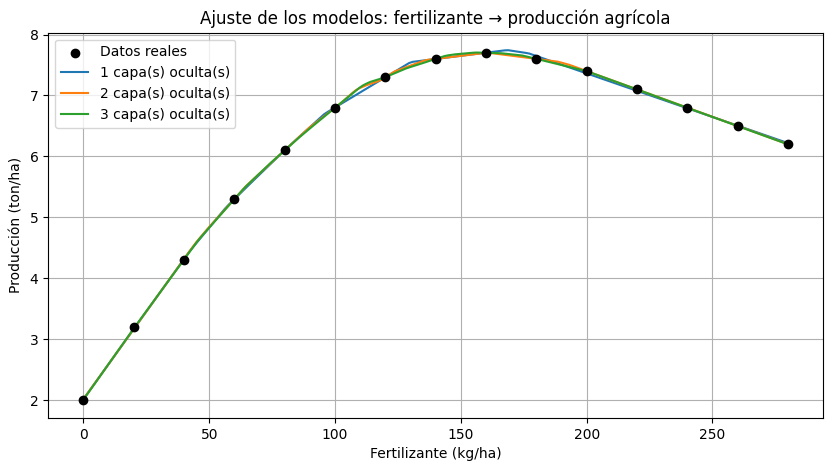

Arquitectura guardada como 'arquitectura_3capas.png'


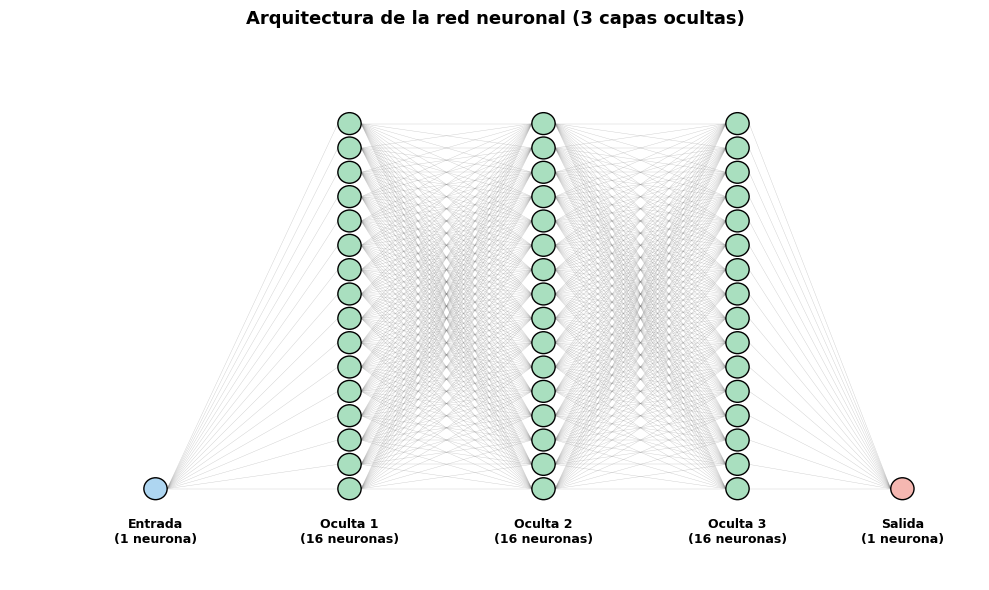


✅ Gráficas generadas.


In [1]:
# ============================================================
# BLOQUE 1: ENTRENAMIENTO Y GRÁFICAS
# Producción agrícola (ton/ha) vs fertilizante (kg/ha)
# Modelos de 1, 2 y 3 capas ocultas
# ============================================================

!pip install pydot graphviz -q
!apt-get install -y graphviz -q

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import os

# ---- Datos: fertilizante (kg/ha) → producción (ton/ha) ----
# Curva con máximo: la producción sube y luego se satura/decae
fertilizante = np.array([0, 20, 40, 60, 80, 100, 120, 140, 160, 180, 200, 220, 240, 260, 280], dtype=float)
produccion   = np.array([2.0, 3.2, 4.3, 5.3, 6.1, 6.8, 7.3, 7.6, 7.7, 7.6, 7.4, 7.1, 6.8, 6.5, 6.2], dtype=float)

# Normalización
f_norm = (fertilizante - fertilizante.mean()) / fertilizante.std()
p_norm = (produccion - produccion.mean()) / produccion.std()

# ---- Función para crear modelos ----
def crear_modelo(num_capas_ocultas):
    model = keras.Sequential()
    model.add(keras.Input(shape=(1,)))
    for _ in range(num_capas_ocultas):
        model.add(layers.Dense(16, activation='relu'))
    model.add(layers.Dense(1))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01),
                  loss='mean_squared_error')
    return model

# ---- Entrenar los tres modelos ----
resultados = {}
historiales = {}

for n in [1, 2, 3]:
    print(f"\n=== Entrenando modelo con {n} capa(s) oculta(s) ===")
    modelo = crear_modelo(n)
    historial = modelo.fit(f_norm, p_norm, epochs=1000, verbose=0)
    historiales[n] = historial.history['loss']
    # Predicción para 100 kg/ha de fertilizante
    x_pred = (100 - fertilizante.mean()) / fertilizante.std()
    pred_norm = modelo.predict(np.array([[x_pred]]), verbose=0)[0][0]
    pred_real = pred_norm * produccion.std() + produccion.mean()
    resultados[n] = {
        'modelo': modelo,
        'prediccion_100kg': float(pred_real),
        'loss_final': float(historial.history['loss'][-1])
    }
    print(f"Producción predicha para 100 kg/ha: {pred_real:.2f} ton/ha | Loss final: {historial.history['loss'][-1]:.6f}")

# ---- Gráfica de pérdida ----
plt.figure(figsize=(10, 5))
for n in [1, 2, 3]:
    plt.plot(historiales[n], label=f'{n} capa(s) oculta(s)')
plt.xlabel('Época')
plt.ylabel('Error cuadrático medio (MSE, normalizado)')
plt.title('Evolución del error durante el entrenamiento')
plt.legend()
plt.grid(True)
plt.savefig('grafica_loss.png', dpi=150, bbox_inches='tight')
plt.show()

# ---- Gráfica de predicciones vs datos reales ----
plt.figure(figsize=(10, 5))
plt.scatter(fertilizante, produccion, color='black', label='Datos reales', zorder=5)
x_test = np.linspace(fertilizante.min(), fertilizante.max(), 200).reshape(-1, 1)
x_test_norm = (x_test - fertilizante.mean()) / fertilizante.std()
for n in [1, 2, 3]:
    y_pred_norm = resultados[n]['modelo'].predict(x_test_norm, verbose=0)
    y_pred = y_pred_norm * produccion.std() + produccion.mean()
    plt.plot(x_test, y_pred, label=f'{n} capa(s) oculta(s)')
plt.xlabel('Fertilizante (kg/ha)')
plt.ylabel('Producción (ton/ha)')
plt.title('Ajuste de los modelos: fertilizante → producción agrícola')
plt.legend()
plt.grid(True)
plt.savefig('grafica_predicciones.png', dpi=150, bbox_inches='tight')
plt.show()

# ---- Arquitectura con plot_model ----
try:
    keras.utils.plot_model(resultados[3]['modelo'],
                           to_file='arquitectura_3capas.png',
                           show_shapes=True,
                           show_layer_names=True,
                           rankdir='LR',
                           dpi=150)
    print("Arquitectura guardada como 'arquitectura_3capas.png'")
except Exception as e:
    print(f"No se pudo generar plot_model: {e}")

# ---- Gráfica esquemática de arquitectura ----
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_xlim(0, 10); ax.set_ylim(0, 6); ax.axis('off')
capas = [
    {'x': 1.5, 'n': 1, 'label': 'Entrada\n(1 neurona)', 'color': '#AED6F1'},
    {'x': 3.5, 'n': 16, 'label': 'Oculta 1\n(16 neuronas)', 'color': '#A9DFBF'},
    {'x': 5.5, 'n': 16, 'label': 'Oculta 2\n(16 neuronas)', 'color': '#A9DFBF'},
    {'x': 7.5, 'n': 16, 'label': 'Oculta 3\n(16 neuronas)', 'color': '#A9DFBF'},
    {'x': 9.2, 'n': 1, 'label': 'Salida\n(1 neurona)', 'color': '#F5B7B1'}
]
for capa in capas:
    y_positions = np.linspace(1, 5, capa['n'])
    for y in y_positions:
        ax.add_patch(plt.Circle((capa['x'], y), 0.12, color=capa['color'], ec='black', zorder=3))
    ax.text(capa['x'], 0.4, capa['label'], ha='center', fontsize=9, fontweight='bold')
for i in range(len(capas)-1):
    x1, n1 = capas[i]['x'], capas[i]['n']
    x2, n2 = capas[i+1]['x'], capas[i+1]['n']
    y1s = np.linspace(1, 5, n1); y2s = np.linspace(1, 5, n2)
    for y1 in y1s:
        for y2 in y2s:
            ax.plot([x1+0.12, x2-0.12], [y1, y2], color='gray', lw=0.3, alpha=0.4, zorder=1)
ax.set_title('Arquitectura de la red neuronal (3 capas ocultas)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('arquitectura_esquematica.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✅ Gráficas generadas.")